# Gradient boosting - LightGBM/XGBoost (owner: Sriniket Deeduvanu)

In [1]:
import os, sys
from pathlib import Path

# --- Colab only: clone the repo and move into it ---
REPO = "ML-Project-Earthquake-Damage"
GITHUB_URL = "https://github.com/ayaanGH06/ML-Project-Earthquake-Damage.git"  # private repo: use a token URL in Colab, never commit it

if "google.colab" in sys.modules and not os.path.exists("src"):
    if not os.path.exists(REPO):
        !git clone {GITHUB_URL}
    %cd {REPO}
    !pip install -q -r requirements.txt

# --- Local Jupyter: notebooks run from notebooks/, so go up to the repo root ---
if Path.cwd().name == "notebooks":
    os.chdir("..")

# --- Data: the 3 CSVs must be in data/raw/ (see README for the download link) ---
DATA_DIR = Path("data/raw")
needed = ["train_values.csv", "train_labels.csv", "test_values.csv"]
missing = [f for f in needed if not (DATA_DIR / f).exists()]
if missing:
    raise FileNotFoundError(
        f"Missing {missing} in {DATA_DIR.resolve()}. "
        "Download them from the Google Drive link in the README and place them in data/raw/."
    )

from src.data import load_raw, train_val_split, build_scaled_preprocessor, build_tree_preprocessor
from src.evaluate import evaluate_model, micro_f1

X, y, X_test = load_raw(DATA_DIR)
X_train, X_val, y_train, y_val = train_val_split(X, y)
print(X_train.shape, X_val.shape)

(208480, 38) (52121, 38)


gradient_boosting: micro-F1 = 0.7277
              precision    recall  f1-score   support

           1       0.69      0.47      0.56      5025
           2       0.72      0.85      0.78     29652
           3       0.75      0.59      0.66     17444

    accuracy                           0.73     52121
   macro avg       0.72      0.64      0.67     52121
weighted avg       0.73      0.73      0.72     52121



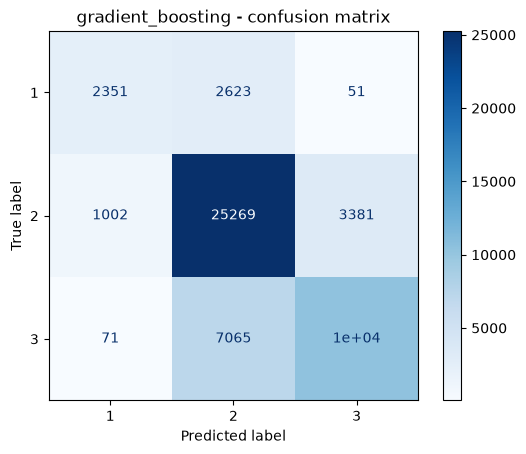

Validation accuracy: 0.7277
Macro F1-score: 0.6666
Training score: 0.7376
Validation score: 0.7277


In [2]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score

gb_model = Pipeline([
    ("preprocessor", build_tree_preprocessor(X_train)),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.1,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    ))
])

gb_model.fit(X_train, y_train)

y_val_pred_gb = gb_model.predict(X_val)

gb_f1 = evaluate_model(
    "gradient_boosting",
    y_val,
    y_val_pred_gb
)

print(f"Validation accuracy: {accuracy_score(y_val, y_val_pred_gb):.4f}")
print(f"Macro F1-score: {f1_score(y_val, y_val_pred_gb, average='macro'):.4f}")
print(f"Training score: {gb_model.score(X_train, y_train):.4f}")
print(f"Validation score: {gb_model.score(X_val, y_val):.4f}")